# Supplementary Fig. 1b: extracellular voltage trace of an infinitesimal electrode and of a finite spherical electrode

**author**: laquitainesteeve@gmail.com

**purpose**: reproduce panel b of Supplementary Fig. 1 of the paper: comparison between an extracellular voltage trace recorded with an infinitesimal electrode (blue) and one obtained with a finite spherical electrode with a 6 um radius (orange), over 2 s. Source data and svg are saved in figures/8_source_data/supp_fig1b/.

**data**: `dataset/01_intermediate/supplementary/lfp_validation/lfp_infinitesimal_vs_finite.csv` (long format: electrode, time in ms, voltage in V), the intermediate data written by the original generating notebook `assets/validation/lookAtLFPs.ipynb` (simulation of `assets/validation/`, see `ReadMe.md` there)

In [1]:
%load_ext autoreload
%autoreload 2
import os
import numpy as np
import pandas as pd
import spikeinterface as si
from matplotlib import pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# set project path
PROJ_PATH = "/home/steeve/steeve/epfl/code/spikebias/"
os.chdir(PROJ_PATH)

# custom package
import subprocess
import tempfile
from PIL import Image
import re

# paths
DATA_PATH = "dataset/01_intermediate/supplementary/lfp_validation/lfp_infinitesimal_vs_finite.csv"

# FIGURE SETTINGS
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 0.5
plt.rcParams["axes.linewidth"] = 0.5
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["xtick.minor.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["ytick.minor.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["xtick.minor.size"] = 2 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.minor.size"] = 2 * 1.1
legend_cfg = {"frameon": False, "handletextpad": 0.5}

# save config
savefig_cfg = {"transparent": True, "dpi": 300}# paths
DATA_PATH = "dataset/01_intermediate/supplementary/lfp_validation/lfp_infinitesimal_vs_finite.csv"

# FIGURE SETTINGS
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 0.5
plt.rcParams["axes.linewidth"] = 0.5
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["xtick.minor.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["ytick.minor.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["xtick.minor.size"] = 2 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.minor.size"] = 2 * 1.1
legend_cfg = {"frameon": False, "handletextpad": 0.5}

# save config
savefig_cfg = {"transparent": True, "dpi": 300}

## Load the voltage traces

In [2]:
%%time

df = pd.read_csv(DATA_PATH)
display(df.groupby("electrode")[["time_ms", "voltage_V"]].agg(["min", "max", "count"]).round(6))

time_ms                    voltage_V                
                  min          max count       min       max count
electrode                                                         
finite            0.0  1999.950008  1723 -0.000305  0.000172  1723
infinitesimal     0.0  1999.950008  1770 -0.000303  0.000172  1770

CPU times: user 7.09 ms, sys: 2.02 ms, total: 9.1 ms
Wall time: 9.08 ms


## Plot, same as the paper's panel b

In [3]:
BLUE_LINE, ORANGE_LINE = (0.1216, 0.4667, 0.7059), (1.0, 0.4980, 0.0549)      # colours of the two traces in the figure

def plot_source_data(df: pd.DataFrame):
    """Voltage trace of an infinitesimal electrode (blue) and of a finite spherical electrode of 6 um radius (orange)"""

    fig, ax = plt.subplots(1, 1, figsize=(2.6, 2.4))
    for name, color, label in [("infinitesimal", BLUE_LINE, "Infinitesimal\nelectrode"), ("finite", ORANGE_LINE, "Finite electrode")]:
        d = df[df["electrode"] == name]
        ax.plot(d["time_ms"], d["voltage_V"], color=color, linewidth=0.7, label=label)

    # aesthetics
    ax.set_xticks([0, 1000, 2000]); ax.set_yticks([1e-4, 0, -1e-4, -2e-4, -3e-4])
    ax.set_yticklabels(["0.0001", "0.0000", "\u22120.0001", "\u22120.0002", "\u22120.0003"])
    ax.set_xlabel("Time (ms)", fontsize=7); ax.set_ylabel("Voltage trace (V)", fontsize=7)
    ax.tick_params(labelsize=7, length=3, width=0.5)
    ax.spines[["right", "top"]].set_visible(False)
    ax.set_title("Infinitesimal vs. Finite electrode", fontsize=6.5, fontweight="bold", color=(0.3, 0.3, 0.3), pad=14)
    leg = ax.legend(frameon=False, loc="upper right", bbox_to_anchor=(1.0, 0.98), fontsize=7, handlelength=2.2, labelspacing=0.3)
    for text, color in zip(leg.get_texts(), [BLUE_LINE, ORANGE_LINE]):
        text.set_color("k")
    return fig, ax

## Plot and save the figure and the source data

CPU times: user 177 ms, sys: 12.9 ms, total: 189 ms
Wall time: 189 ms


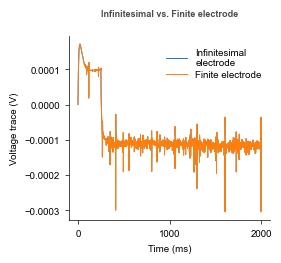

In [4]:
%%time

# plot
fig, ax = plot_source_data(df)

# save figure
os.makedirs("figures/8_source_data/supp_fig1b", exist_ok=True)
plt.savefig("figures/8_source_data/supp_fig1b/supp_fig1b.svg", bbox_inches="tight", **savefig_cfg)

# save source data
df.to_excel("figures/8_source_data/supp_fig1b/supp_fig1b.xlsx", index=False)

## Check: replot from the saved source data

CPU times: user 64.3 ms, sys: 0 ns, total: 64.3 ms
Wall time: 64.1 ms


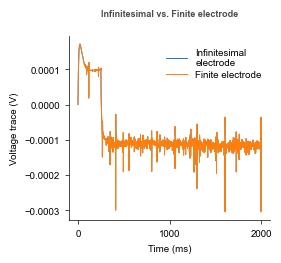

In [5]:
%%time

df = pd.read_excel("figures/8_source_data/supp_fig1b/supp_fig1b.xlsx")
fig, ax = plot_source_data(df)